# 01 - Data preparation and text preprocessing
**Project 4: Customer Review Intelligence (Amazon Fine Food Reviews)**

This notebook covers PDF steps 1-4: scope, cleaning, text preprocessing and exploratory text analysis.
The heavy lifting lives in tested modules under `reviews/`; this notebook runs them, shows what they did, and
explains the choices.

| Step | Module | Output |
|---|---|---|
| 2. Cleaning and labels | `reviews.prepare` | `data/processed/reviews_clean.parquet`, `reports/data_quality.json` |
| 3. Text preprocessing | `reviews.preprocess` | `data/processed/reviews_text.parquet`, `reports/text_report.json` |
| 4. Exploratory analysis | `reviews.explore` | `reports/eda_summary.json`, `reports/figures/*.png` |

**Scope.** Task: classify reviews as positive or negative (neutral 3-star reviews are dropped), then find topics
and aspect-level pain points. Target: binary macro-F1 above 0.88.

## 0. Setup
Set the flags below to `True` to (re)run a stage. With `False` the notebook just reads the saved outputs, so it opens in seconds.

In [10]:
import json
import logging
import os
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

# Notebooks live in notebooks/, the project root is one level up (the modules and data paths are relative to it).
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

from reviews.config import ProjectConfig
from reviews.logging_utils import configure_logging

configure_logging("WARNING")                      # keep the notebook quiet; use "INFO" to watch the pipeline
base = ProjectConfig()
CFG = replace(base, paths=replace(base.paths, root=ROOT))
pd.set_option("display.max_columns", 30, "display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Project root:", ROOT)

RUN_CLEANING = False        # about a minute: reads data/raw/Reviews.csv
RUN_PREPROCESSING = False   # about 10-30 minutes: spaCy lemmatisation of every review
RUN_EDA = False             # a few minutes: tables and charts

def read_json(path: Path) -> dict:
    """Read a saved report, or stop with a hint about which step creates it."""
    if not path.is_file():
        raise FileNotFoundError(f"{path} not found; set the matching RUN_ flag to True (or run the earlier steps first).")
    return json.loads(path.read_text(encoding="utf-8"))

Project root: c:\Projects\review-intelligence-nlp


## 1. Cleaning and labelling (step 2)
Rules, in order (each logs how many rows it removed): drop reviews with no usable text, invalid ratings, duplicate
review rows, **duplicate review texts** (the same review is copied across product variants, which would leak between
train and test), and non-English reviews. Stars become labels: 1-2 negative, 3 neutral, 4-5 positive.

In [11]:
if RUN_CLEANING:
    from reviews import prepare
    prepare.run(CFG)
quality = read_json(CFG.paths.quality_report_path)
print(f"Raw rows {quality['rows_raw']:,} -> clean rows {quality['rows_clean']:,} ({quality['share_kept']:.1%} kept)")
print("Date range:", quality["date_range"], "| products:", quality["unique_products"], "| users:", quality["unique_users"])
funnel = pd.DataFrame(quality["cleaning_steps"])
funnel

Raw rows 568,454 -> clean rows 392,945 (69.1% kept)
Date range: ['1999-10-08', '2012-10-26'] | products: 67480 | users: 255870


,step,dropped,remaining
0,unusable_text,0,568454
1,invalid_rating_or_date,0,568454
2,duplicate_review,1205,567249
3,duplicate_text,174076,393173
4,non_english,228,392945


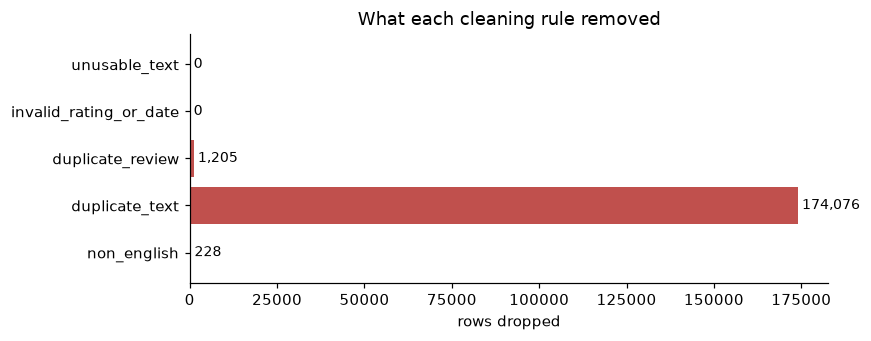

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(funnel["step"][::-1], funnel["dropped"][::-1], color="#c0504d")
ax.set_xlabel("rows dropped")
ax.set_title("What each cleaning rule removed")
for y, v in enumerate(funnel["dropped"][::-1]):
    ax.text(v, y, f" {v:,}", va="center", fontsize=9)
plt.tight_layout(); plt.show()

### Class balance and review length
The positive class dominates, which is why **macro-F1** (not accuracy) is the metric: it gives the minority negative class equal weight.

,counts,share,imbalance_ratio
negative,56969.0,0.1450,NaN
neutral,29712.0,0.0756,NaN
positive,306264.0,0.7794,NaN
majority_to_minority,NaN,NaN,10.31


Binary rows: 363,233 | positive share: 0.8432


,median,p95,max
negative,63.0,220.0,2149.0
neutral,70.0,257.0,3432.0
positive,54.0,209.0,2520.0


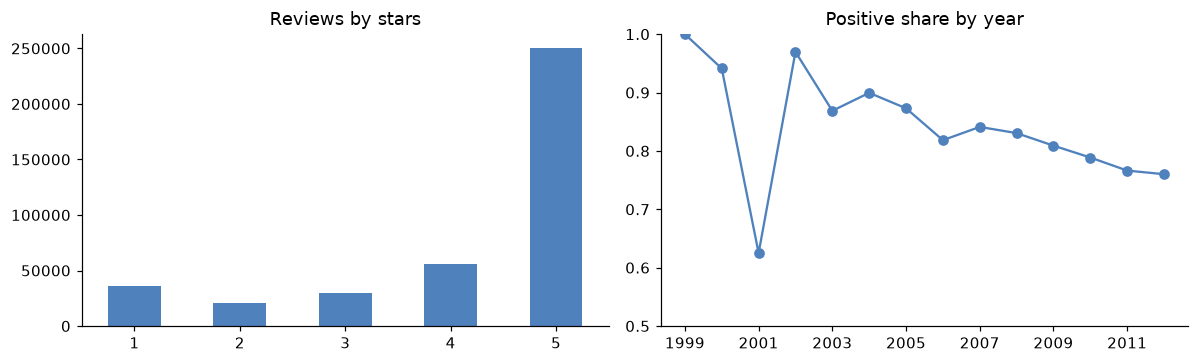

In [13]:
balance = pd.DataFrame(quality["class_balance_three_class"])
display(balance)
print("Binary rows:", f"{quality['binary_rows']:,}", "| positive share:", quality["binary_positive_share"])
stars = pd.Series(quality["stars"])
words = pd.DataFrame(quality["words_per_review"]["by_sentiment"]).T
display(words)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
stars.plot.bar(ax=axes[0], color="#4f81bd", rot=0, title="Reviews by stars")
pd.Series(quality["positive_share_per_year"]).plot(ax=axes[1], marker="o", color="#4f81bd", title="Positive share by year", ylim=(0.5, 1))
plt.tight_layout(); plt.show()

## 2. Text preprocessing (step 3)
Two text columns are kept on purpose:

* `Text` (raw): used by DistilBERT, which has its own tokeniser and needs punctuation and casing.
* `text_clean` (lower-cased, markup removed, contractions expanded, stop-words removed, lemmatised with spaCy):
  used by TF-IDF models, topic models and word statistics.

Negation words (`not`, `no`, `never`) and intensifiers (`very`, `but`) are **kept** because dropping them flips the
meaning of "not good".

In [14]:
from reviews import text as rt

examples = [
    "I <b>can't</b> believe how GOOD this coffee is!!! Arrived on time & well packed.<br />Will buy again.",
    "Not worth the price. The cookies were stale and the box was damaged, never again.",
]
for example in examples:
    print("RAW  :", example)
    print("CLEAN:", rt.clean_text(example, CFG.text))
    print()
print("Stop-word list size:", len(rt.stopword_set(CFG.text)), "| kept on purpose:", [w for w in ("not", "no", "never", "but", "very") if w not in rt.stopword_set(CFG.text)])

RAW  : I <b>can't</b> believe how GOOD this coffee is!!! Arrived on time & well packed.<br />Will buy again.
CLEAN: i cannot believe how good this coffee is arrived on time well packed will buy again

RAW  : Not worth the price. The cookies were stale and the box was damaged, never again.
CLEAN: not worth the price the cookies were stale and the box was damaged never again

Stop-word list size: 297 | kept on purpose: ['not', 'no', 'never', 'but', 'very']


392,945 reviews | vocabulary 90,427 | tokens seen once 42,669
Median words before: 57.0 -> median tokens after: 26.0
Reviews empty after cleaning: 1 | reviews with negation: 0.6438
Negation / intensifier counts kept: {'not': 452890, 'no': 74300, 'never': 27010, 'but': 256645, 'very': 117104}


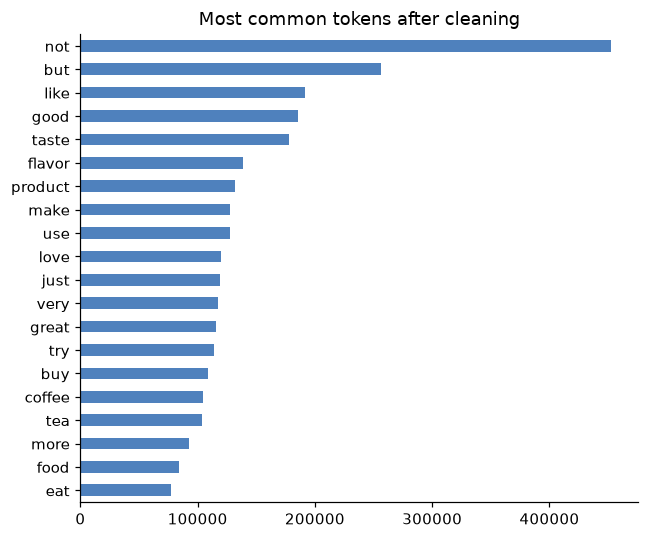

In [15]:
if RUN_PREPROCESSING:
    from reviews import preprocess
    preprocess.run(CFG)
report = read_json(CFG.paths.text_report_path)
print(f"{report['rows']:,} reviews | vocabulary {report['vocabulary_size']:,} | tokens seen once {report['tokens_seen_once']:,}")
print("Median words before:", report["words_before_median"], "-> median tokens after:", report["tokens_per_review"]["median"])
print("Reviews empty after cleaning:", report["empty_after_cleaning"], "| reviews with negation:", report["reviews_with_negation_share"])
print("Negation / intensifier counts kept:", report["kept_sentiment_words"])
pd.Series(report["top_tokens"]).head(20).iloc[::-1].plot.barh(figsize=(6, 5), color="#4f81bd", title="Most common tokens after cleaning")
plt.tight_layout(); plt.show()

In [16]:
text_path = CFG.paths.text_path(sample=False)
sample = pd.read_parquet(text_path, columns=["Text", "text_clean", "n_words", "n_tokens", "sentiment"]).sample(5, random_state=42)
sample.assign(Text=sample["Text"].str.slice(0, 120), text_clean=sample["text_clean"].str.slice(0, 120))

,Text,text_clean,n_words,n_tokens,sentiment
376753,Puppy doesn't like it. I have to add Zukes tr...,puppy not like add zuke treat eat amazon kind ...,32,14,negative
131970,I bought these last Christmas based on the rev...,buy christmas base review never fast order more,20,8,positive
306583,The product is a good product. No complaints t...,product good product no complaint item descrip...,112,48,positive
59112,taste texture is incredible. my favorite candy...,taste texture incredible favorite candy soooo ...,26,14,positive
109908,It does not work well. It is too wide and too ...,not work too wide too tight mole unable make work,20,10,negative


## 3. Exploratory text analysis (step 4)
Which words, phrases and lengths separate negative from positive reviews, and how does sentiment move over time?

Keys in the EDA summary: rows, length, yearly, top_words, distinctive_negative, distinctive_positive, months_plotted, ngram_sample_per_class


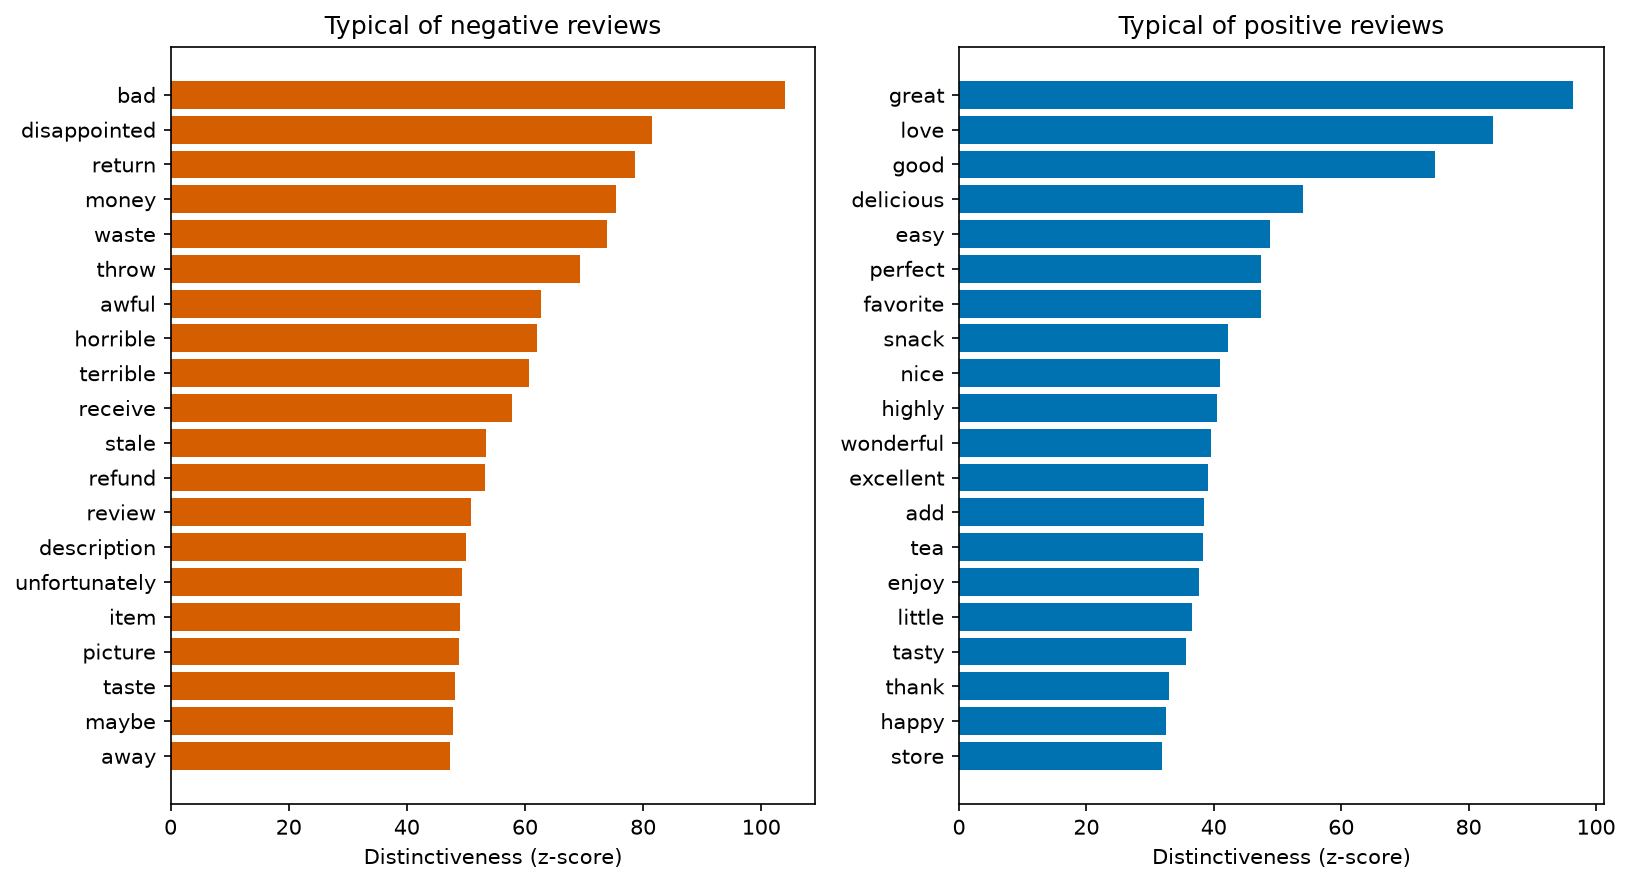

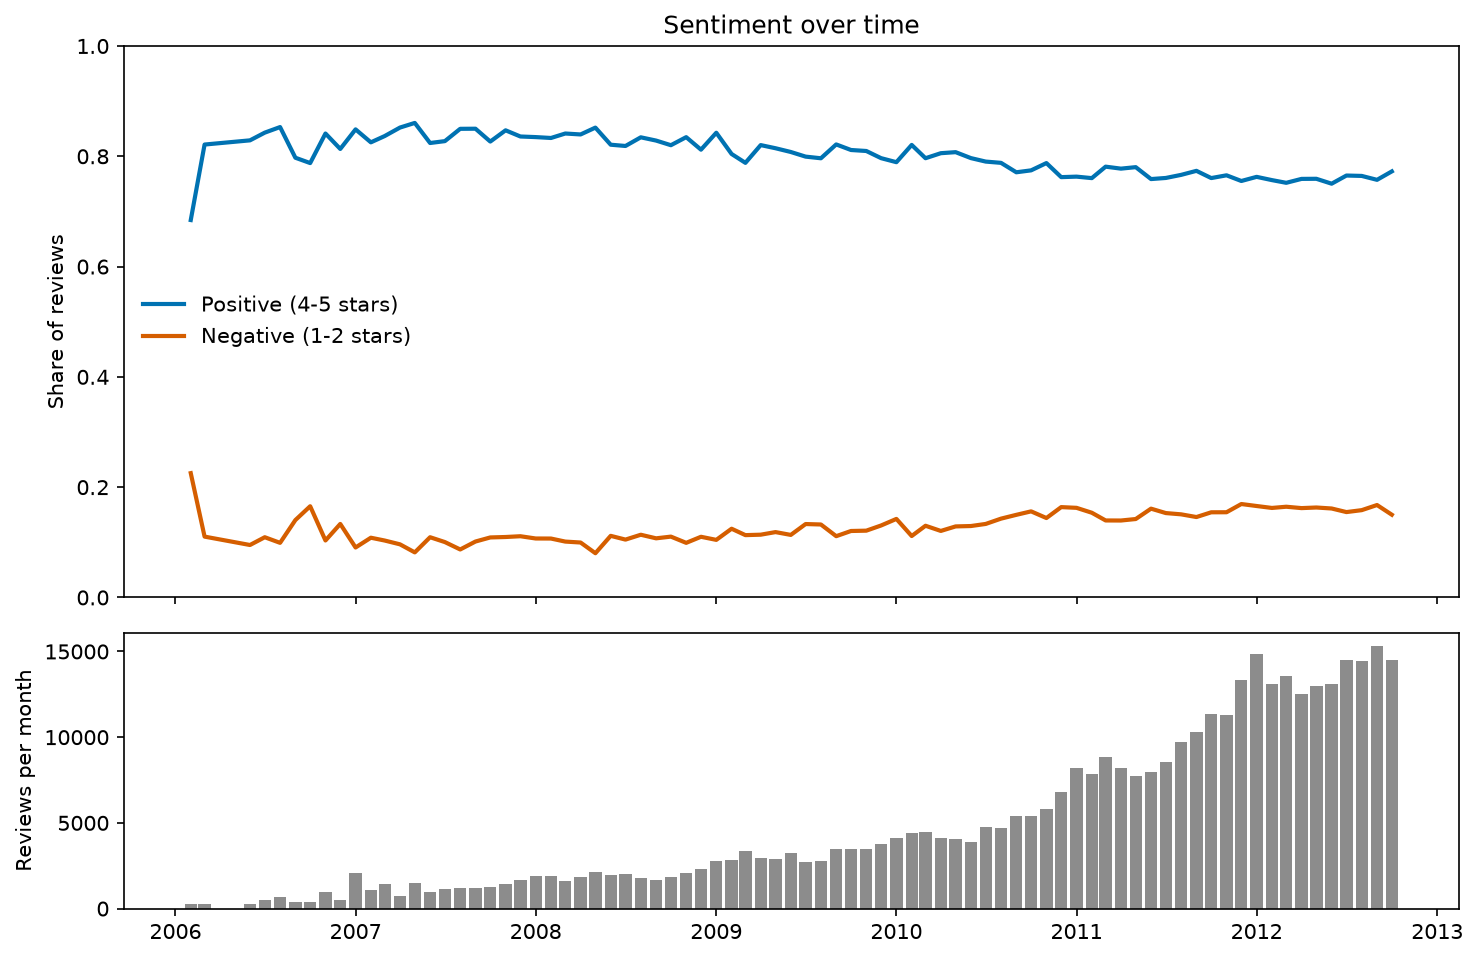

In [17]:
if RUN_EDA:
    from reviews import explore
    explore.run(CFG)
eda = read_json(CFG.paths.eda_summary_path)
print("Keys in the EDA summary:", ", ".join(eda))
for name in ("distinctive_words.png", "sentiment_trend.png"):
    path = CFG.paths.figures_path / name
    if path.is_file():
        display(Image(filename=str(path)))

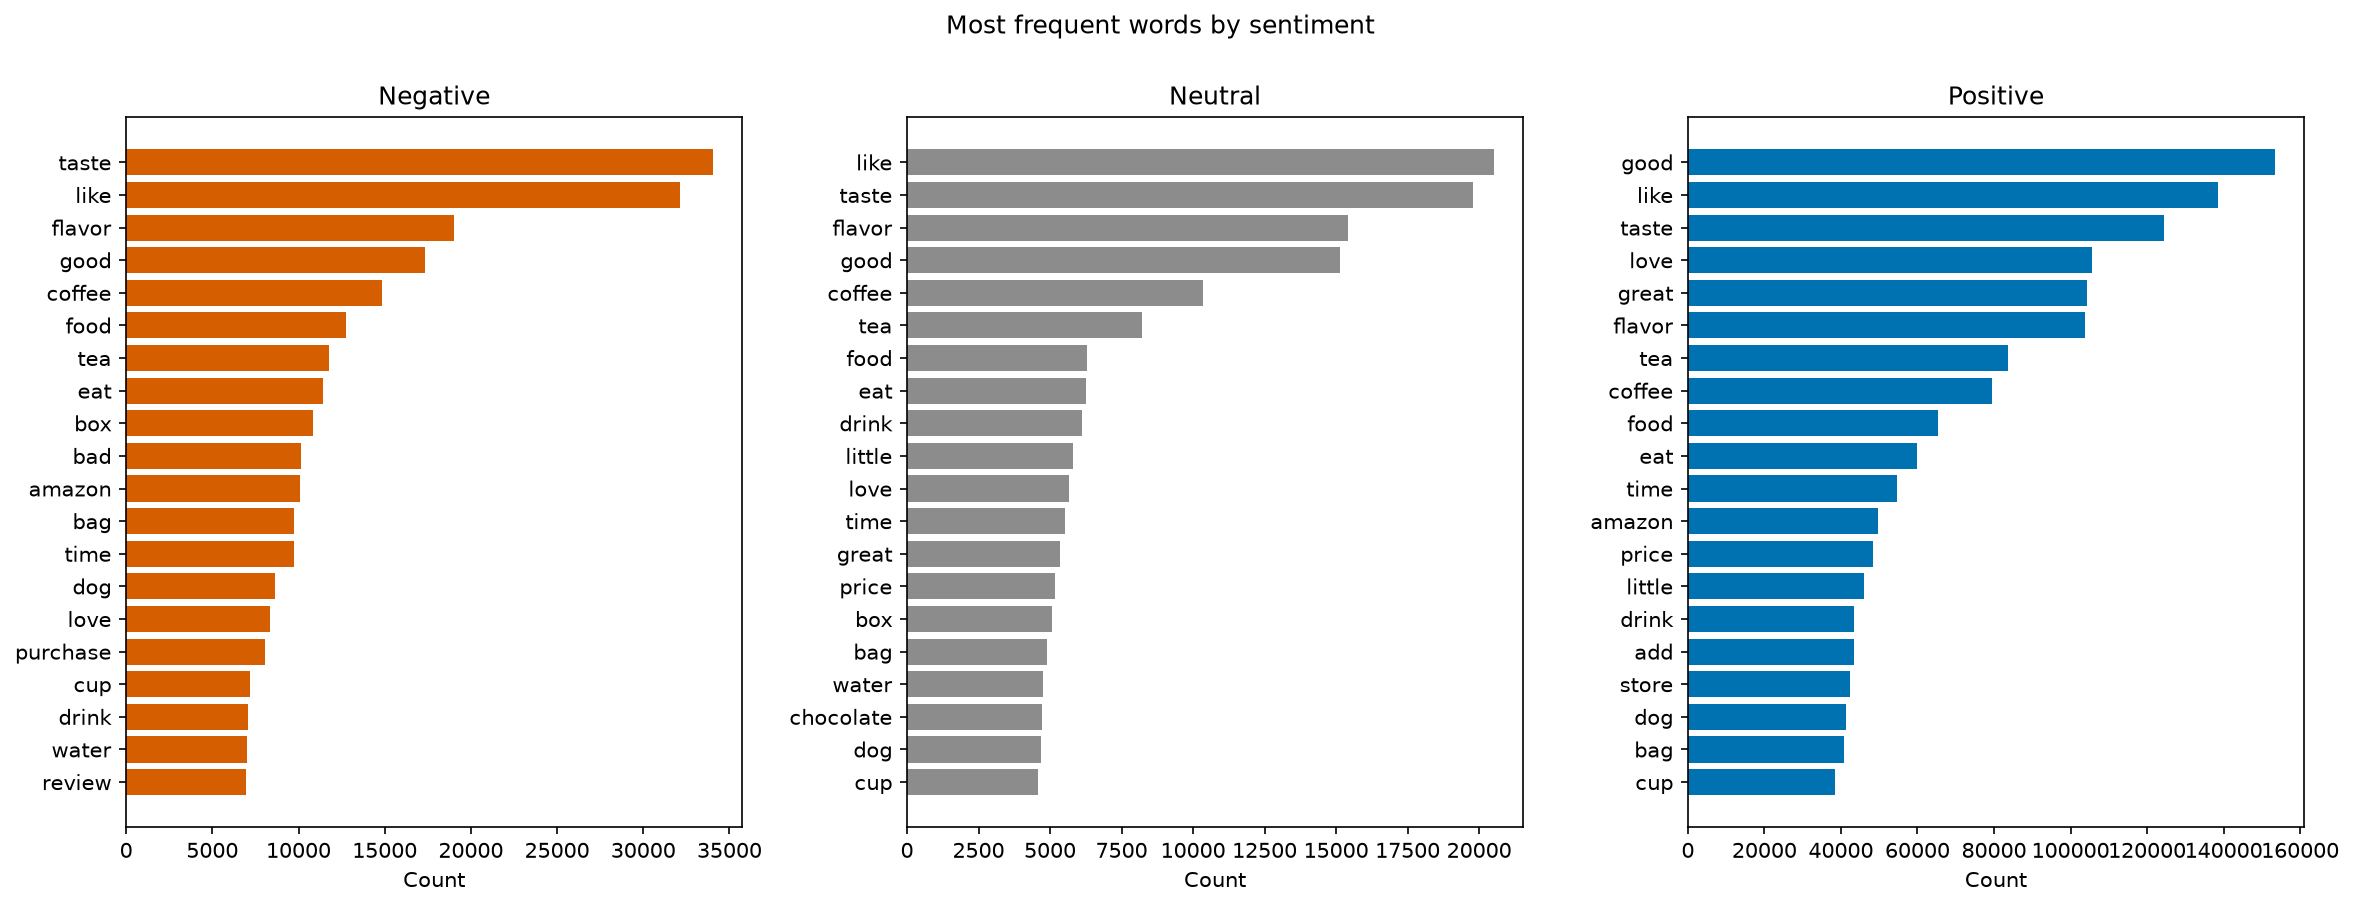

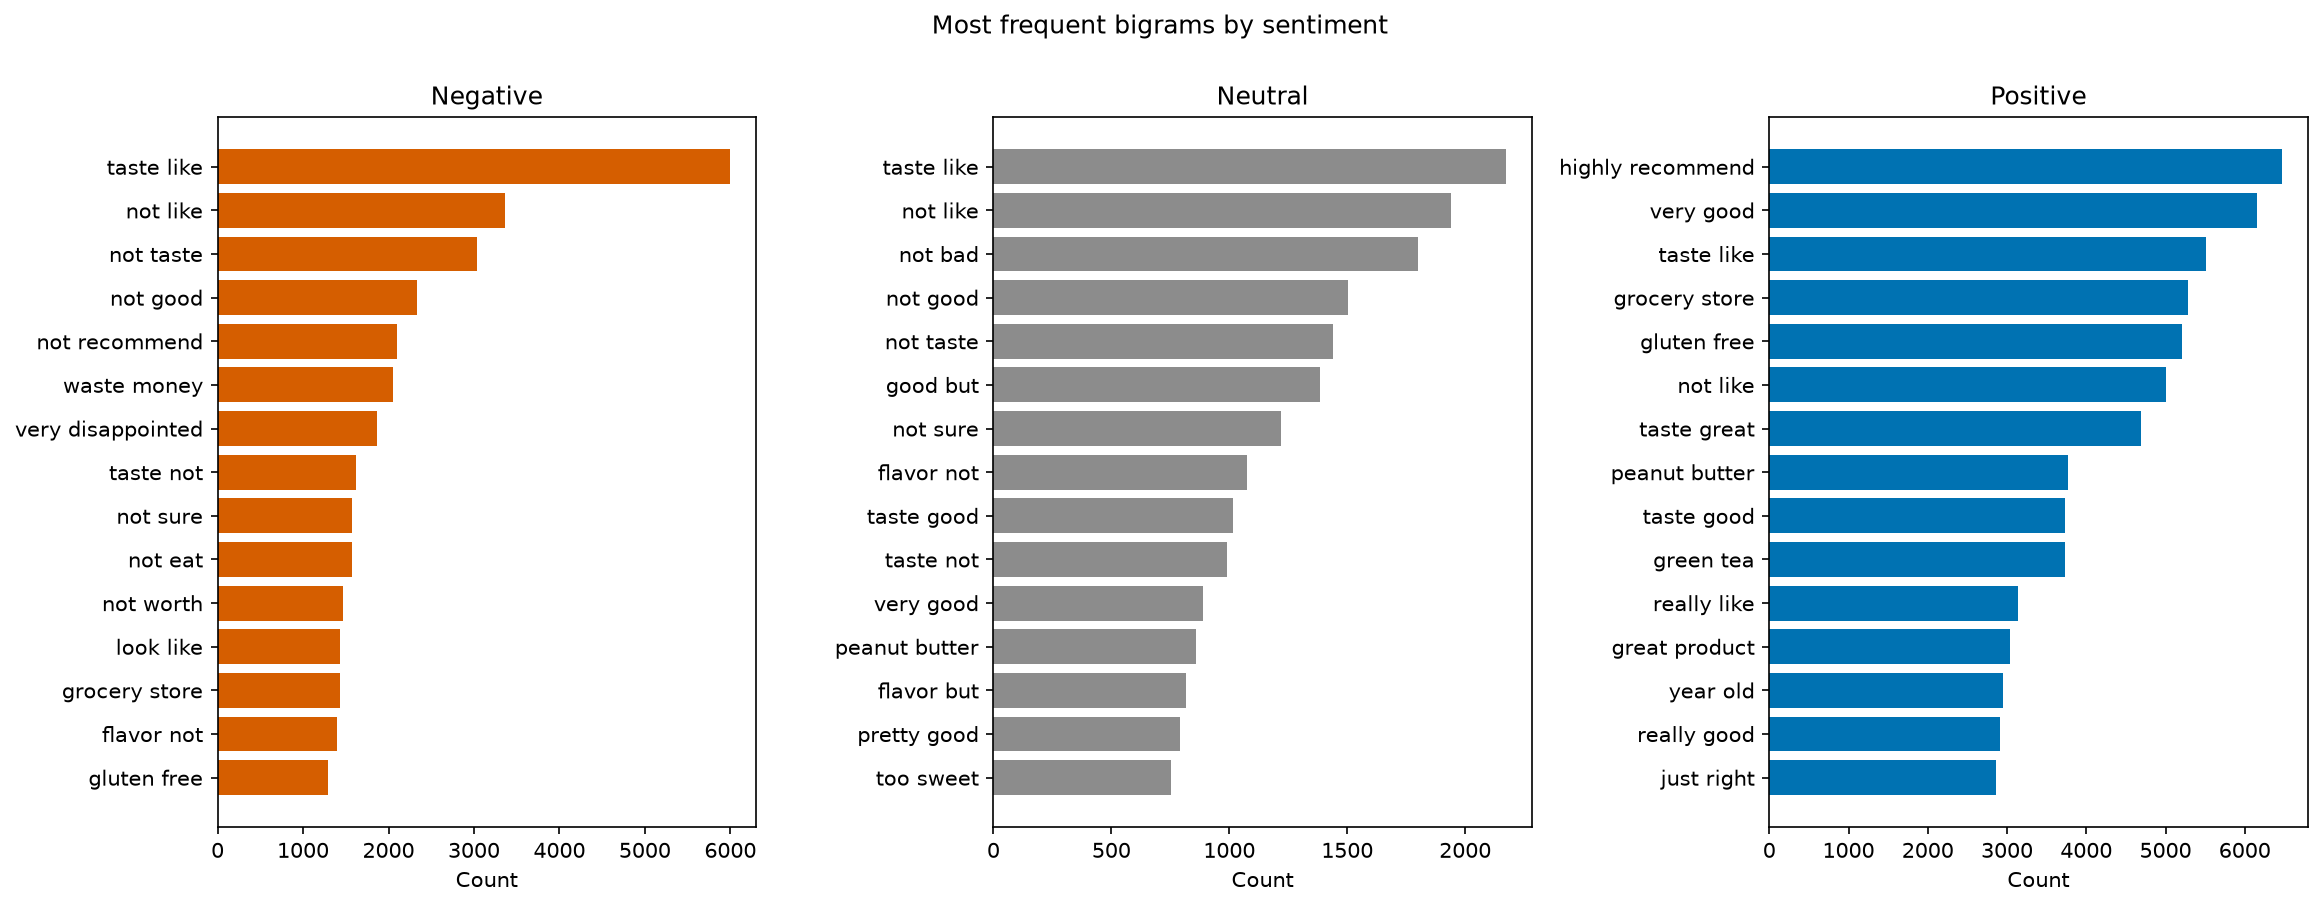

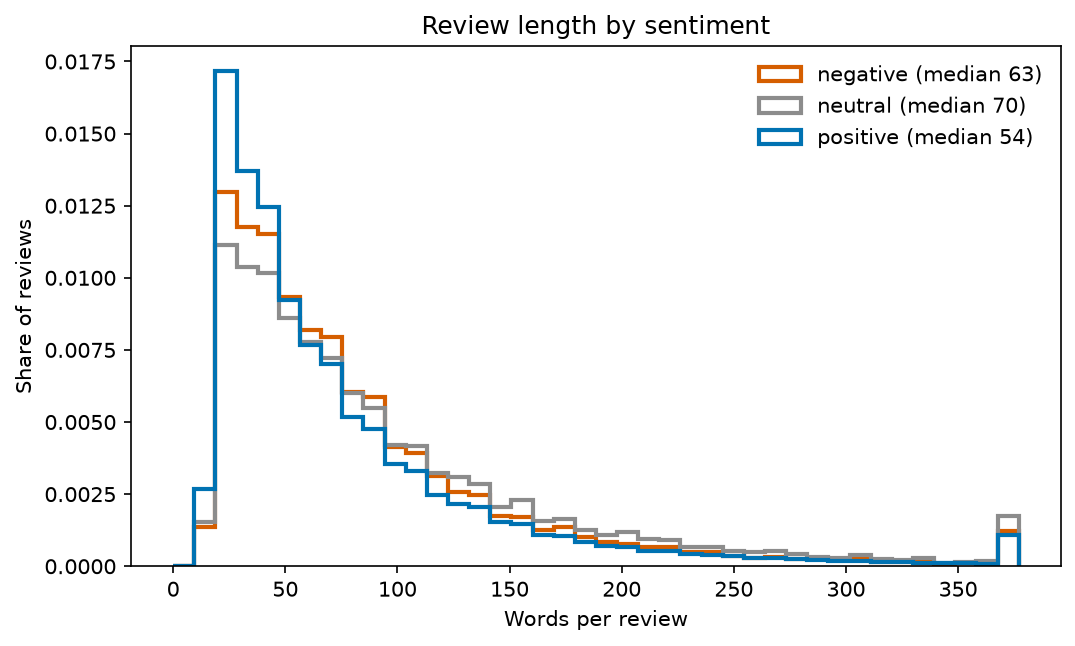

In [18]:
for name in ("top_words_by_sentiment.png", "top_bigrams.png", "length_distribution.png"):
    path = CFG.paths.figures_path / name
    if path.is_file():
        display(Image(filename=str(path)))

## 4. What this means for modelling
* The data is imbalanced, so models are compared on **macro-F1**, with a stratified 70/15/15 split (`random_state=42`).
* Duplicate texts are removed before splitting, so the test score is not inflated by copies of training reviews.
* Raw text goes to the transformer, `text_clean` to everything else.

Next: `02_model_training.ipynb`.